<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/05_fcn_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — FCN Segmentation

## 1. Chargement des données

Nous entraînons un Fully Convolutional Network (FCN) pour la segmentation sémantique des anomalies routières.

Nous utilisons les mêmes données et les mêmes conditions d'évaluation que pour CNN Baseline et U-Net afin de comparer les performances.

Le FCN produit un masque de segmentation en utilisant des couches convolutives.

In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/deep learning P")
SPLIT_PATH = PROJECT_DIR / "split_manifest.csv"

df = pd.read_csv(SPLIT_PATH)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))
print("Device :", device)

Mounted at /content/drive
Train : 42
Validation : 9
Test : 9
Device : cuda


## 2. Préparation des données

Nous réutilisons le même prétraitement que pour CNN Baseline et U-Net :

- Redimensionnement à 256 × 256 avec padding.
- Normalisation des pixels entre 0 et 1.
- Masques binaires : 0 (normal) et 1 (anomalie).
- Augmentation uniquement pour l'entraînement.

Les DataLoaders regroupent les images par batches de 4.

In [2]:
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = (256, 256)

def preprocess_image(path):
    image = Image.open(path).convert("RGB")
    image = ImageOps.pad(
        image, IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )
    return np.asarray(image, dtype=np.float32) / 255.0


def preprocess_mask(path):
    mask = Image.open(path).convert("L")
    mask = ImageOps.pad(
        mask, IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )
    return (np.asarray(mask) == 2).astype(np.float32)


def augment_image_mask(image, mask, rng):
    if rng.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    image = np.clip(image * rng.uniform(0.8, 1.2), 0, 1)

    mean = image.mean(axis=(0, 1), keepdims=True)
    image = np.clip(
        (image - mean) * rng.uniform(0.8, 1.2) + mean, 0, 1
    )

    return image.astype(np.float32), mask


class RoadAnomalyDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_mask(row["mask"])

        if self.augment:
            image, mask = augment_image_mask(
                image, mask, self.rng
            )

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask


# DataLoaders
train_loader = DataLoader(
    RoadAnomalyDataset(train_df, augment=True),
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    RoadAnomalyDataset(val_df),
    batch_size=4,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    RoadAnomalyDataset(test_df),
    batch_size=4,
    shuffle=False,
    num_workers=0
)

# Vérification rapide
images, masks = next(iter(train_loader))

print("Images :", images.shape)
print("Masques :", masks.shape)
print("Device :", device)

Images : torch.Size([4, 3, 256, 256])
Masques : torch.Size([4, 1, 256, 256])
Device : cuda


## 3. Construction du modèle FCN

Nous construisons un FCN-8s simplifié pour la segmentation des anomalies routières.

- **Encodeur :** extrait les caractéristiques des images à différentes résolutions.
- **Skip connections :** combinent les prédictions de plusieurs niveaux par addition.
- **Upsampling :** agrandit le résultat pour retrouver la taille de l'image.

Le modèle produit un score pour chaque pixel afin de distinguer les zones normales des anomalies.

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class FCN8s(nn.Module):

    def __init__(self):
        super().__init__()

        # Encodeur
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.block4 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.pool = nn.MaxPool2d(2)

        # Prédictions à différentes résolutions
        self.score8 = nn.Conv2d(128, 1, kernel_size=1)
        self.score4 = nn.Conv2d(64, 1, kernel_size=1)
        self.score2 = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):

        # Extraction des caractéristiques
        x1 = self.block1(x)                 # 256 x 256
        x2 = self.block2(self.pool(x1))     # 128 x 128
        x3 = self.block3(self.pool(x2))     # 64 x 64
        x4 = self.block4(self.pool(x3))     # 32 x 32

        # Prédiction à 1/8 de la résolution
        score = self.score8(x4)

        # Fusion avec le niveau 1/4
        score = F.interpolate(
            score, size=x3.shape[2:],
            mode="bilinear", align_corners=False
        )
        score = score + self.score4(x3)

        # Fusion avec le niveau 1/2
        score = F.interpolate(
            score, size=x2.shape[2:],
            mode="bilinear", align_corners=False
        )
        score = score + self.score2(x2)

        # Retour à la résolution originale
        score = F.interpolate(
            score, size=x.shape[2:],
            mode="bilinear", align_corners=False
        )

        return score


# Créer le FCN sur le GPU
model = FCN8s().to(device)

# Vérifier les dimensions
images, masks = next(iter(train_loader))

with torch.no_grad():
    outputs = model(images.to(device))

print("Entrée :", images.shape)
print("Sortie :", outputs.shape)
print("Masques réels :", masks.shape)
print(
    "Nombre de paramètres :",
    sum(p.numel() for p in model.parameters())
)

Entrée : torch.Size([4, 3, 256, 256])
Sortie : torch.Size([4, 1, 256, 256])
Masques réels : torch.Size([4, 1, 256, 256])
Nombre de paramètres : 293747


## 4. Fonction de perte et optimiseur

Nous utilisons la même configuration que pour les modèles précédents :

- **BCE Loss :** mesure les erreurs de classification des pixels.
- **Dice Loss :** aide à segmenter les anomalies malgré le déséquilibre des classes.
- **Adam :** optimise les paramètres avec un learning rate de 0.001.

La fonction de perte combine BCE et Dice avec un poids de 0.5 chacune.

In [4]:
import torch
import torch.nn as nn

# BCE Loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(1, 2, 3))
    union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + smooth) / (union + smooth)

    return 1 - dice.mean()


# Combinaison BCE + Dice
def combined_loss(logits, targets):
    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice


# Optimiseur Adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Vérification sur un batch
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

outputs = model(images)
loss = combined_loss(outputs, masks)

print("BCE Loss :", round(bce_loss(outputs, masks).item(), 4))
print("Dice Loss :", round(dice_loss(outputs, masks).item(), 4))
print("Combined Loss :", round(loss.item(), 4))
print("Optimizer : Adam")
print("Learning rate :", optimizer.param_groups[0]["lr"])

BCE Loss : 0.6587
Dice Loss : 0.9224
Combined Loss : 0.7906
Optimizer : Adam
Learning rate : 0.001


## 5. Entraînement et validation du FCN

Nous entraînons le FCN sur les 42 images Train et suivons ses performances sur les 9 images Validation.

- **Epochs :** maximum 30.
- **Batch size :** 4.
- **Early Stopping :** arrêt après 6 époques sans amélioration.
- **Checkpoint :** sauvegarde du modèle avec la meilleure Validation Loss.

Nous suivons les pertes d'entraînement et de validation pour analyser l'apprentissage.

In [5]:
import torch
from pathlib import Path

EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

# Dossier de sauvegarde
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "fcn_best.pth"

for epoch in range(EPOCHS):

    # Entraînement
    model.train()
    train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = combined_loss(outputs, masks)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Sauvegarder le meilleur modèle
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(model.state_dict(), MODEL_PATH)
    else:
        patience_counter += 1

    # Early Stopping
    if patience_counter >= PATIENCE:
        print("\nEarly Stopping activated.")
        break

print("\nTraining completed!")
print("Best Validation Loss :", round(best_val_loss, 4))
print("Model saved at :", MODEL_PATH)

Epoch 01/30 | Train Loss: 0.6845 | Val Loss: 0.6037
Epoch 02/30 | Train Loss: 0.5990 | Val Loss: 0.5857
Epoch 03/30 | Train Loss: 0.5955 | Val Loss: 0.5881
Epoch 04/30 | Train Loss: 0.5728 | Val Loss: 0.5659
Epoch 05/30 | Train Loss: 0.5681 | Val Loss: 0.5326
Epoch 06/30 | Train Loss: 0.5523 | Val Loss: 0.5285
Epoch 07/30 | Train Loss: 0.5545 | Val Loss: 0.5244
Epoch 08/30 | Train Loss: 0.5695 | Val Loss: 0.5405
Epoch 09/30 | Train Loss: 0.5571 | Val Loss: 0.5361
Epoch 10/30 | Train Loss: 0.5448 | Val Loss: 0.5233
Epoch 11/30 | Train Loss: 0.5500 | Val Loss: 0.5195
Epoch 12/30 | Train Loss: 0.5415 | Val Loss: 0.5170
Epoch 13/30 | Train Loss: 0.5485 | Val Loss: 0.5168
Epoch 14/30 | Train Loss: 0.5383 | Val Loss: 0.5134
Epoch 15/30 | Train Loss: 0.5394 | Val Loss: 0.5073
Epoch 16/30 | Train Loss: 0.5369 | Val Loss: 0.5044
Epoch 17/30 | Train Loss: 0.5319 | Val Loss: 0.4949
Epoch 18/30 | Train Loss: 0.5161 | Val Loss: 0.4698
Epoch 19/30 | Train Loss: 0.4942 | Val Loss: 0.4612
Epoch 20/30 

## 6. Analyse des courbes d'apprentissage

Nous visualisons les pertes Train et Validation du FCN pour étudier sa convergence et identifier un éventuel surapprentissage.

La meilleure Validation Loss est de 0.3839, obtenue à l'époque 27.

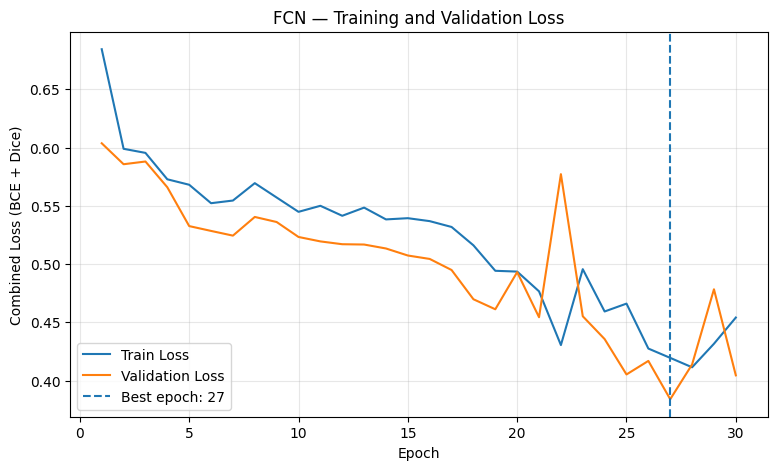

Best epoch : 27
Best Validation Loss : 0.3839


In [6]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses) + 1)
best_epoch = int(np.argmin(val_losses)) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Loss (BCE + Dice)")
plt.title("FCN — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best epoch :", best_epoch)
print("Best Validation Loss :", round(min(val_losses), 4))

## 7. Évaluation du FCN

Nous évaluons le meilleur modèle FCN sur les 9 images de test.

Métriques utilisées :
- **IoU :** mesure le chevauchement entre prédiction et masque réel.
- **Dice :** mesure la similarité des masques.
- **Precision :** proportion des pixels prédits anormaux qui le sont réellement.
- **Recall :** proportion des pixels anormaux correctement détectés.

Nous utilisons le même seuil de 0.5 que pour CNN Baseline et U-Net.

In [7]:
import torch

# Charger le meilleur modèle FCN
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

TP = FP = FN = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        preds = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        TP += (preds & targets).sum().item()
        FP += (preds & ~targets).sum().item()
        FN += (~preds & targets).sum().item()

eps = 1e-7

iou = TP / (TP + FP + FN + eps)
dice = 2 * TP / (2 * TP + FP + FN + eps)
precision = TP / (TP + FP + eps)
recall = TP / (TP + FN + eps)

print("FCN — Test Results")
print(f"IoU       : {iou:.4f}")
print(f"Dice      : {dice:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

FCN — Test Results
IoU       : 0.2478
Dice      : 0.3972
Precision : 0.3270
Recall    : 0.5058


## 8. Visualisation des prédictions

Nous comparons les images originales, les masques réels et les prédictions du FCN.

Cette visualisation permet d'identifier les anomalies correctement détectées, les anomalies manquées et les faux positifs.

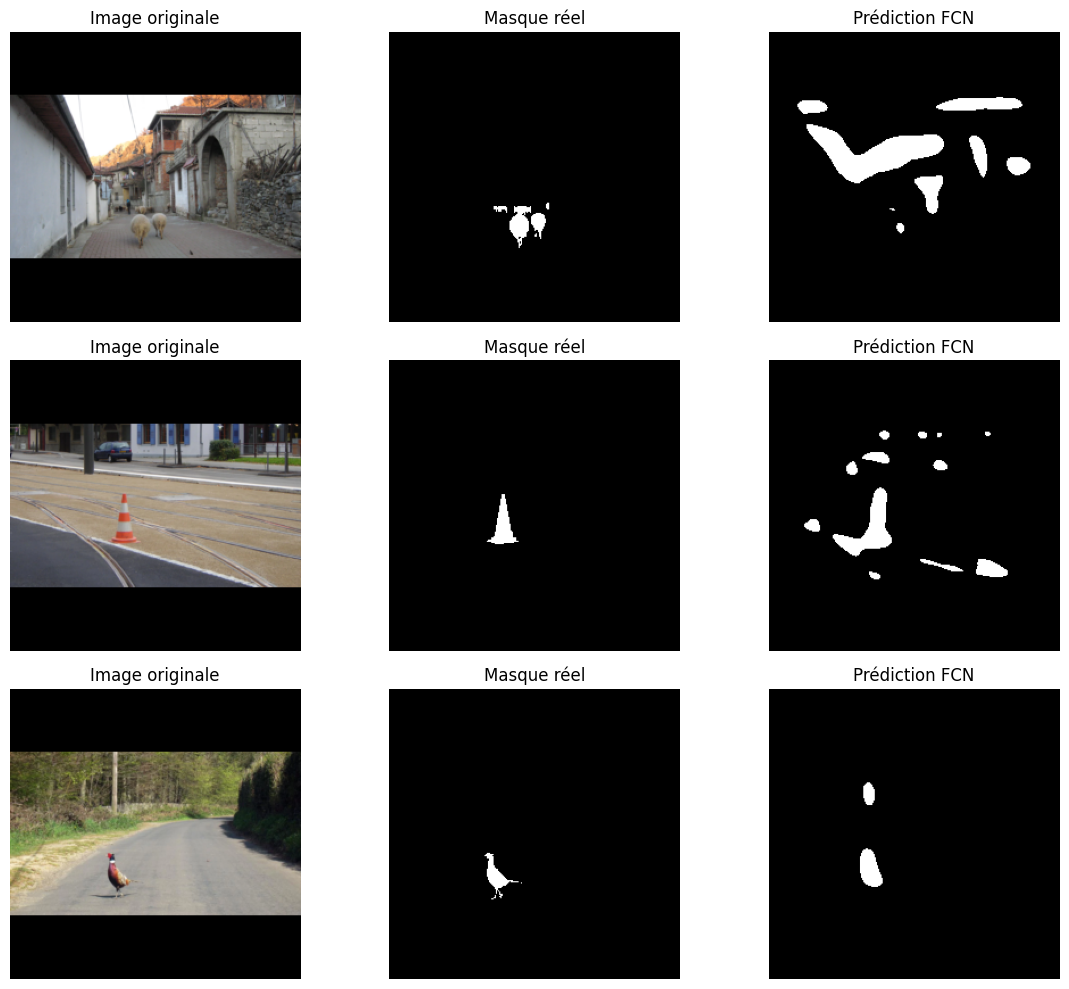

In [8]:
import matplotlib.pyplot as plt
import torch

model.eval()
test_dataset = test_loader.dataset

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(3):
        image, mask = test_dataset[i]

        logits = model(image.unsqueeze(0).to(device))
        pred = torch.sigmoid(logits) >= 0.5

        image_np = image.permute(1, 2, 0).cpu().numpy()
        mask_np = mask.squeeze().cpu().numpy()
        pred_np = pred.squeeze().cpu().numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Image originale")

        axes[i, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Masque réel")

        axes[i, 2].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Prédiction FCN")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Conclusion

Le FCN-8s simplifié a été entraîné pendant 30 époques. Le meilleur modèle a été obtenu à l'époque 27, avec une Validation Loss de 0.3839.

### Comparaison des modèles

| Métrique | CNN Baseline | U-Net | FCN |
|---|---|---|---|
| IoU | 0.1925 | 0.2707 | 0.2478 |
| Dice | 0.3229 | 0.4260 | 0.3972 |
| Precision | 0.4104 | 0.3582 | 0.3270 |
| Recall | 0.2661 | 0.5257 | 0.5058 |

### Analyse

Le FCN améliore le IoU, le Dice et le Recall par rapport au CNN Baseline.

Cependant, U-Net reste le modèle le plus performant en IoU, Dice et Recall.

Les visualisations montrent que le FCN détecte partiellement plusieurs obstacles, mais produit encore des faux positifs et des erreurs de localisation.

### Conclusion

Parmi les trois architectures évaluées, U-Net obtient les meilleurs résultats globaux de segmentation sur notre ensemble de test.

Les performances restent limitées, notamment en raison de la petite taille du dataset et des difficultés de détection des obstacles.

L'étape suivante consiste à expérimenter une architecture U-Net avec un encodeur pré-entraîné afin d'évaluer l'apport du transfer learning.